# code_036 · Prediction, explanation and causal claims

**Book:** section 7.5. These are synthetic mechanism experiments, not observed structural performance, safety assessment, a causal study or an estimator leaderboard. Each experiment states which cases are unseen and which outcomes are available. Fits and preprocessing use training observations only. Development curves support diagnosis; final outcomes are opened only after the stated rule is fixed. Constructed identities and stress cases are not held-out population estimates.

Restart and run all cells. All imports, helpers and data generation are here; no ordinary-run files, network, API key, GPU or private module is required. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [traceability guide](../CHAPTER_07_GUIDE.md), [execution evidence](../CHAPTER_07_EXECUTION.md) and [permanent registry](../CODE_EXAMPLES.md#code_036). Reference environment: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute for execution and 30–60 minutes for interpretation. These scoped labs disclose relevant controls rather than cover every constructor parameter.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=736;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 736


<a id="mechanisms"></a>
## The same observed table can support different causal stories

Recorded variables are maintenance A (0/1) and a later failure Y (0/1). Hidden U represents preparedness: P(U=1)=.5, P(A=1|U=1)=.8 and P(A=1|U=0)=.2. In mechanism 1, failure probability is .3-.25*U regardless of A. Maintenance therefore has zero effect for every unit under the shared-noise potential outcomes, yet maintained units have lower observed failure risk because U influences both treatment and outcome.

Mechanism 2 instead randomizes A with probability .5 and makes failure probability .25-.15*A. It has the same joint distribution of recorded (A,Y) as mechanism 1 but a true average risk reduction .15. The equality concerns only these recorded variables; observing U or additional informative evidence could distinguish the mechanisms. The simulator author knows the mechanism, while a learner restricted to (A,Y) does not.


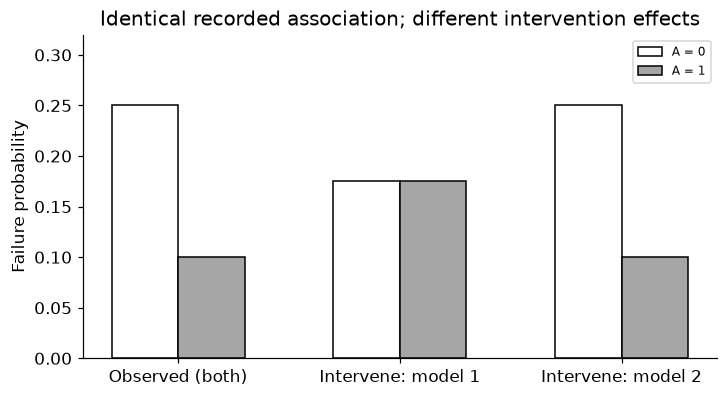

In [2]:
# Exact population calculations; no sampling error obscures the construction.
observed=np.zeros((2,2))
for u in [0,1]:
 pa=.8 if u else .2;py=.3-.25*u
 for a in [0,1]:
  for outcome in [0,1]:observed[a,outcome]+=.5*(pa if a else 1-pa)*(py if outcome else 1-py)
alternative=np.array([[.5*(1-.25),.5*.25],[.5*(1-.10),.5*.10]])
assert np.allclose(observed,alternative) and np.isclose(observed.sum(),1)
risk_observed=observed[:,1]/observed.sum(1);do_risk_1=np.full(2,.5*.3+.5*.05);do_risk_2=np.array([.25,.10])
assert np.allclose(risk_observed,[.25,.10]) and np.isclose(np.diff(do_risk_1)[0],0)
assert np.isclose(np.diff(do_risk_2)[0],-.15)
fig,ax=plt.subplots(figsize=(6.5,3.5));positions=np.arange(3);width=.3
ax.bar(positions-width/2,[risk_observed[0],do_risk_1[0],do_risk_2[0]],width,color='white',edgecolor='black',label='A = 0')
ax.bar(positions+width/2,[risk_observed[1],do_risk_1[1],do_risk_2[1]],width,color='.65',edgecolor='black',label='A = 1')
ax.set(xticks=positions,xticklabels=['Observed (both)','Intervene: model 1','Intervene: model 2'],ylabel='Failure probability',ylim=(0,.32),title='Identical recorded association; different intervention effects');ax.legend(fontsize=8);plt.show()
RESULTS['observed_joint_A_Y']=observed.tolist();RESULTS['observed_failure_risk_A0_A1']=risk_observed.tolist();RESULTS['intervention_risk_model1']=do_risk_1.tolist();RESULTS['intervention_risk_model2']=do_risk_2.tolist()


<a id="prediction"></a>
## Fit a valid prediction task without changing its meaning

Generate 5000 independent cases from mechanism 1. The prediction occurs after the maintenance decision has been recorded and before the later failure, so A is an available predictive input. Roles: 3000 training, 1000 development, 1000 final. Hidden preparedness is not supplied to the model. Fit fixed LogisticRegression(C=1,solver='lbfgs',max_iter=1000) on A only, with a training finding-frequency baseline. Its coefficient explains the fitted log odds association. Flipping an input in that fitted formula is not the same as intervening on maintenance in the data-generating process.


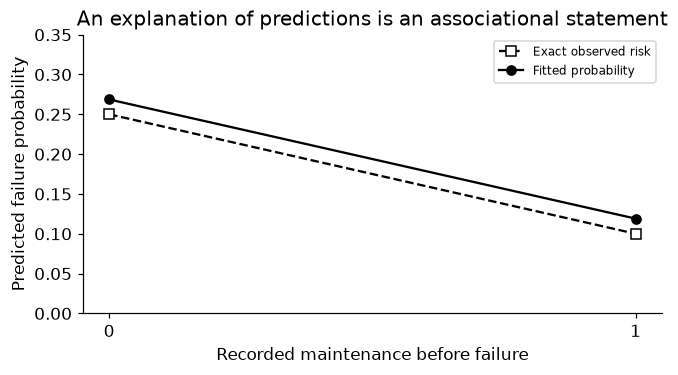

In [3]:
from sklearn.linear_model import LogisticRegression
N=5000;U=rng.binomial(1,.5,N);A=rng.binomial(1,np.where(U==1,.8,.2));noise=rng.random(N);Y=(noise<(.3-.25*U)).astype(int)
tr=np.arange(3000);dv=np.arange(3000,4000);te=np.arange(4000,5000)
model=LogisticRegression(C=1.,solver='lbfgs',max_iter=1000).fit(A[tr,None],Y[tr]);p_pair=model.predict_proba(np.array([[0],[1]]))[:,1]
assert not set(tr)&set(dv) and not set(tr)&set(te) and not set(dv)&set(te)
assert model.n_iter_[0]<1000 and model.coef_.shape==(1,1)
from scipy.special import expit
assert np.allclose(p_pair,expit(model.intercept_[0]+model.coef_[0,0]*np.array([0,1])))
fig,ax=plt.subplots(figsize=(6,3.3));ax.plot([0,1],risk_observed,'ks--',mfc='white',label='Exact observed risk');ax.plot([0,1],p_pair,'ko-',label='Fitted probability')
ax.set(xticks=[0,1],xlabel='Recorded maintenance before failure',ylabel='Predicted failure probability',ylim=(0,.35),title='An explanation of predictions is an associational statement');ax.legend(fontsize=8);plt.show()
RESULTS['logistic_coefficient']=float(model.coef_[0,0]);RESULTS['fitted_probability_A0_A1']=p_pair.tolist()


<a id="final"></a>
## Open final predictive outcomes once

Final binary log loss checks prediction under the observed assignment process. It cannot tell which of the two causal mechanisms generated a recorded (A,Y) table. No threshold, effect estimate or model setting is selected from this final sample.


In [4]:
def logloss(y,p):
 p=np.clip(p,1e-12,1-1e-12);return float(-np.mean(y*np.log(p)+(1-y)*np.log1p(-p)))
p=model.predict_proba(A[te,None])[:,1];score=logloss(Y[te],p);baseline=logloss(Y[te],float(Y[tr].mean()))
assert np.isfinite([score,baseline]).all() and p.shape==(1000,)
RESULTS['final_log_loss']=score;RESULTS['baseline_final_log_loss']=baseline


<a id="intervention"></a>
## A separate randomized simulator check

Generate fresh preparedness and potential outcomes from mechanism 1, then randomize maintenance independently. Potential Y(0)=Y(1) for every simulated case, so the paired simulator effect is exactly zero. The observed risk difference in the finite randomized sample may fluctuate. This is an author-known controlled simulation, not identification from the original observational logs or a real-world maintenance study. Consistency, assignment assumptions, outcome definitions and interference would need scrutiny in an application.


In [5]:
count=20000;u=rng.binomial(1,.5,count);v=rng.random(count);Y0=(v<(.3-.25*u)).astype(int);Y1=Y0.copy();random_A=rng.binomial(1,.5,count);observed_random=np.where(random_A,Y1,Y0)
assert np.array_equal(Y1,Y0) and np.mean(Y1-Y0)==0
random_difference=float(observed_random[random_A==1].mean()-observed_random[random_A==0].mean())
observational_difference=float(risk_observed[1]-risk_observed[0])
assert abs(random_difference)<.03 and np.isclose(observational_difference,-.15)
RESULTS['randomized_simulator_risk_difference']=random_difference;RESULTS['mechanism1_true_average_effect']=0.;RESULTS['observational_risk_difference']=observational_difference;print(RESULTS)


{'observed_joint_A_Y': [[0.37499999999999994, 0.125], [0.45, 0.049999999999999996]], 'observed_failure_risk_A0_A1': [0.25000000000000006, 0.09999999999999999], 'intervention_risk_model1': [0.175, 0.175], 'intervention_risk_model2': [0.25, 0.1], 'logistic_coefficient': -1.0002467216758537, 'fitted_probability_A0_A1': [0.2686206217239512, 0.11900578269320293], 'final_log_loss': 0.43621872780899923, 'baseline_final_log_loss': 0.46188872812844345, 'randomized_simulator_risk_difference': -0.005832708047822266, 'mechanism1_true_average_effect': 0.0, 'observational_risk_difference': -0.15000000000000008}


<a id="exercises"></a>
## Exercises and hints

1. State a causal graph for each mechanism and explain exactly which recorded distributions agree.
2. Add measured preparedness and derive a standardized conditional comparison under explicitly stated identification assumptions; do not assume every real confounder is measured.
3. Predict before maintenance has been chosen. Explain why the recorded action is then unavailable as an ordinary feature.
4. Change treatment costs, adherence, timing or interference. State which intervention effect you now mean.
5. Explain a coefficient or local model perturbation without converting it into a claim about changing a physical system.

**Hints:** conditioning on A changes the preparedness mixture; intervening in mechanism 1 does not. A good predictive score and a clear model explanation cannot select between observationally identical intervention stories. See Pearl's author-hosted [causal inference overview](https://ftp.cs.ucla.edu/pub/stat_ser/r350.pdf). This toy does not supply a general adjustment strategy or identify maintenance effects in field data.


In [6]:
summary={'example_id':'code_036','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['observed maintenance association versus intervention', 'actual predictive model and coefficient interpretation', 'two observationally identical causal mechanisms', 'explicit unobserved confounding', 'randomized simulator check without field identification'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["observed maintenance association versus intervention", "actual predictive model and coefficient interpretation", "two observationally identical causal mechanisms", "explicit unobserved confounding", "randomized simulator check without field identification"], "elapsed_seconds": 0.319, "example_id": "code_036", "hardware": "Darwin arm64 CPU", "results": {"baseline_final_log_loss": 0.46188872812844345, "final_log_loss": 0.43621872780899923, "fitted_probability_A0_A1": [0.2686206217239512, 0.11900578269320293], "intervention_risk_model1": [0.175, 0.175], "intervention_risk_model2": [0.25, 0.1], "logistic_coefficient": -1.0002467216758537, "mechanism1_true_average_effect": 0.0, "observational_risk_difference": -0.15000000000000008, "observed_failure_risk_A0_A1": [0.25000000000000006, 0.09999999999999999], "observed_joint_A_Y": [[0.37499999999999994, 0.125], [0.45, 0.049999999999999996]], "randomized_simulator_risk_difference": -0.0058327080